# HPC LSTM Forecaster — Per-Node Multivariate Time-Series Prediction

This notebook trains one LSTM forecaster per HPC node on the V6 engineered 1-minute telemetry.

## What it does

1. Loads `hpc_features_1min_v6.parquet` and `labels_1min_v6.parquet`.
2. Selects a set of key metrics (CPU, memory, network, disk, load, iowait).
3. Builds sliding windows (lookback = 60 min → horizon = 1 min).
4. Splits chronologically: 70% train / 15% val / 15% test (same boundaries as V7).
5. Trains a small LSTM per node to predict the **next-minute value** of all metrics.
6. Evaluates forecast accuracy (MAE / RMSE / MAPE) and compares it to a persistence baseline.
7. *(Bonus)* Uses forecast residuals as an unsupervised anomaly score and evaluates it against the V6 labels.

## How this fits with V7 Isolation Forest

- **Isolation Forest (V7)** — detects unusual *current* multivariate snapshots (point anomalies, novel regimes).
- **LSTM (this notebook)** — learns the *temporal dynamics* and forecasts the next step. Residuals flag values that deviate from the model's expectation.
- The two detectors are **complementary** and can be combined at the alert-fusion layer.

The LSTM never uses anomaly labels as inputs. Labels are used only for *evaluation* of the residual detector.

In [1]:
# Run only if something is missing
%pip install -q pandas numpy pyarrow matplotlib scikit-learn torch joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json
import time
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------------------------------------------
# Paths (same as V7)
# ------------------------------------------------------------------
DATA_DIR = Path(r"C:/Users/Admin/Documents/chpc/capstone project/data/feature_engineering_duckdb_v6")
MODEL_DIR = Path(r"C:/Users/Admin/Documents/chpc/capstone project/models")
REPORT_DIR = DATA_DIR / "v8_lstm_report"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TELEMETRY_FILE = DATA_DIR / "hpc_features_1min_v6.parquet"
LABEL_FILE     = DATA_DIR / "labels_1min_v6.parquet"

# ------------------------------------------------------------------
# Forecast configuration
# ------------------------------------------------------------------
# These are the metrics we forecast. The LSTM sees all of them as input
# and predicts the next-step values of all of them.
FEATURE_COLUMNS = [
    "cpu_utilisation_pct_mean",
    "memory_used_pct_mean",
    "network_rx_mib_s_mean",
    "network_tx_mib_s_mean",
    "disk_read_mib_s_mean",
    "disk_write_mib_s_mean",
    "node_load1_per_core_mean",
    "iowait_pct_mean",
]

LOOKBACK  = 60     # 60 minutes of history
HORIZON   = 1      # predict next minute (change to e.g. 5 for multi-step)
BATCH_SIZE = 256
EPOCHS     = 40
LEARNING_RATE = 1e-3
HIDDEN_SIZE = 64
NUM_LAYERS  = 1
DROPOUT     = 0.2
PATIENCE    = 8

# Chronological split fractions (match V7)
TRAIN_FRACTION      = 0.70
VALIDATION_FRACTION = 0.15

# Anomaly-detection-on-residuals settings
RESIDUAL_THRESHOLD_SIGMA = 3.0   # flag if max |z| of any feature >= 3

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Telemetry exists:", TELEMETRY_FILE.exists())
print("Labels exist:", LABEL_FILE.exists())

Device: cpu
Telemetry exists: True
Labels exist: True


## 2. Load and inspect data

We load the full engineered 1-minute feature table and the label table. The
join must be one-to-one on `(node_id, minute_utc)`.

In [3]:
telemetry = pd.read_parquet(TELEMETRY_FILE)
labels    = pd.read_parquet(LABEL_FILE)

telemetry["minute_utc"] = pd.to_datetime(telemetry["minute_utc"], utc=True)
labels["minute_utc"]    = pd.to_datetime(labels["minute_utc"],    utc=True)

# Verify required feature columns exist
missing = [c for c in FEATURE_COLUMNS if c not in telemetry.columns]
if missing:
    raise KeyError(f"Missing expected feature columns in telemetry: {missing}")

# Verify one-to-one join
key_audit = telemetry[["node_id", "minute_utc"]].merge(
    labels[["node_id", "minute_utc"]],
    on=["node_id", "minute_utc"], how="outer", indicator=True
)
assert (key_audit["_merge"] == "both").all(), \
    f"Telemetry/label keys do not align: {key_audit['_merge'].value_counts().to_dict()}"

# Merge labels (we won't feed them to the LSTM; used only for evaluation)
df = telemetry.merge(
    labels[["node_id", "minute_utc",
            "is_any_anomaly", "operational_event_window",
            "is_benchmark_active", "event_id"]],
    on=["node_id", "minute_utc"], how="inner"
).sort_values(["node_id", "minute_utc"]).reset_index(drop=True)

# Chronological split boundaries — same as V7 (by unique timestamps)
unique_times = np.array(sorted(df["minute_utc"].unique()))
n_times = len(unique_times)
train_end = int(n_times * TRAIN_FRACTION)
val_end   = int(n_times * (TRAIN_FRACTION + VALIDATION_FRACTION))
TRAIN_END_TIME = unique_times[train_end - 1]
VAL_END_TIME   = unique_times[val_end - 1]

print(f"Rows: {len(df):,}")
print(f"Nodes: {sorted(df['node_id'].unique())}")
print(f"Time range: {df['minute_utc'].min()} to {df['minute_utc'].max()}")
print(f"Train end: {TRAIN_END_TIME}")
print(f"Val end:   {VAL_END_TIME}")
print(f"Feature columns: {FEATURE_COLUMNS}")

display(df[["node_id", "minute_utc"] + FEATURE_COLUMNS].head())

Rows: 80,640
Nodes: ['compute001', 'compute002', 'compute003', 'headnode']
Time range: 2026-10-18 00:00:00+00:00 to 2026-10-31 23:59:00+00:00
Train end: 2026-10-27 19:11:00+00:00
Val end:   2026-10-29 21:35:00+00:00
Feature columns: ['cpu_utilisation_pct_mean', 'memory_used_pct_mean', 'network_rx_mib_s_mean', 'network_tx_mib_s_mean', 'disk_read_mib_s_mean', 'disk_write_mib_s_mean', 'node_load1_per_core_mean', 'iowait_pct_mean']


,node_id,minute_utc,cpu_utilisation_pct_mean,memory_used_pct_mean,network_rx_mib_s_mean,network_tx_mib_s_mean,disk_read_mib_s_mean,disk_write_mib_s_mean,node_load1_per_core_mean,iowait_pct_mean
0,compute001,2026-10-18 00:00:00+00:00,0.066678,2.634052,0.000203,0.000873,0.000347,0.037153,0.0,0.013892
1,compute001,2026-10-18 00:01:00+00:00,0.014585,2.638119,0.000200,0.000883,0.000000,0.000000,0.0,0.000000
2,compute001,2026-10-18 00:02:00+00:00,0.022916,2.638119,0.000220,0.000878,0.000000,0.000000,0.0,0.000000
3,compute001,2026-10-18 00:03:00+00:00,0.022916,2.638119,0.000183,0.000873,0.000000,0.000000,0.0,0.000000
4,compute001,2026-10-18 00:04:00+00:00,0.018751,2.637735,0.000198,0.000883,0.000000,0.000000,0.0,0.000000


## 3. Per-node data preparation

For each node we:

1. Sort by timestamp and select the forecast features.
2. Forward-fill then back-fill missing values (dropping anything still NaN).
3. Split into train / val / test using the chronological boundaries.
4. Fit a `StandardScaler` on **training data only**, then transform all splits.
5. Build sliding windows `(X, y)` inside each split.

Windows are built *after* the split so no window straddles the train/val or
val/test boundary.

In [4]:
# ==================================================================
# UPGRADED CELL 4: Multi-Horizon Windows + Activity-Weighted Split
# ==================================================================
from torch.utils.data import WeightedRandomSampler

HORIZONS = [1, 15, 30, 60]  # 1m (real-time residual), 15m, 30m, 60m (1h early warning)
MAX_HORIZON = max(HORIZONS) # 60 minutes ahead

def build_multi_horizon_windows(values, labels_series, lookback, horizons):
    """
    values        : (T, F) scaled time series
    labels_series : (T,) binary anomaly/failure indicator
    Returns:
      X           : (N, lookback, F)
      y           : (N, len(horizons), F)
      warn_60m    : (N,) 1 if ANY anomaly occurs in (t+1 ... t+60), else 0
    """
    max_h = max(horizons)
    T, F = values.shape
    n = T - lookback - max_h + 1
    if n <= 0:
        return (
            np.empty((0, lookback, F), dtype=np.float32),
            np.empty((0, len(horizons), F), dtype=np.float32),
            np.empty((0,), dtype=np.int64),
        )

    X = np.stack([values[i : i + lookback] for i in range(n)], axis=0)
    # Extract targets at t + h - 1 after the lookback window
    y = np.stack(
        [[values[i + lookback + h - 1] for h in horizons] for i in range(n)],
        axis=0,
    )
    # 1-hour early warning ground truth: does an anomaly happen within the next 60 mins?
    warn_60m = np.array(
        [
            int(labels_series[i + lookback : i + lookback + max_h].max() > 0)
            for i in range(n)
        ],
        dtype=np.int64,
    )
    return X.astype(np.float32), y.astype(np.float32), warn_60m


NODES = sorted(df["node_id"].dropna().unique())
node_data = {}

for node in NODES:
    sub = df[df["node_id"] == node].sort_values("minute_utc").reset_index(drop=True)
    sub[FEATURE_COLUMNS] = sub[FEATURE_COLUMNS].ffill().bfill()
    sub = sub.dropna(subset=FEATURE_COLUMNS).reset_index(drop=True)

    # Combined ground-truth target for evaluation only
    raw_label = (
        (sub["is_any_anomaly"].fillna(0).astype(int) > 0)
        | (sub["operational_event_window"].fillna(0).astype(int) > 0)
    ).astype(int).values

    mask_train = sub["minute_utc"] <= TRAIN_END_TIME
    mask_val   = (sub["minute_utc"] > TRAIN_END_TIME) & (sub["minute_utc"] <= VAL_END_TIME)
    mask_test  = sub["minute_utc"] > VAL_END_TIME

    raw_train = sub.loc[mask_train, FEATURE_COLUMNS].values
    raw_val   = sub.loc[mask_val,   FEATURE_COLUMNS].values
    raw_test  = sub.loc[mask_test,  FEATURE_COLUMNS].values

    # Fit StandardScaler on training data, but floor scale_ so near-constant idle
    # features don't explode into z > 50 during active test benchmarks
    scaler = StandardScaler().fit(raw_train)
    min_scale = np.array([5.0, 2.0, 0.5, 0.5, 0.05, 0.1, 0.1, 0.5])  # realistic floor per metric
    scaler.scale_ = np.maximum(scaler.scale_, min_scale)

    X_tr, y_tr, w60_tr = build_multi_horizon_windows(
        scaler.transform(raw_train), raw_label[mask_train], LOOKBACK, HORIZONS
    )
    X_va, y_va, w60_va = build_multi_horizon_windows(
        scaler.transform(raw_val), raw_label[mask_val], LOOKBACK, HORIZONS
    )
    X_te, y_te, w60_te = build_multi_horizon_windows(
        scaler.transform(raw_test), raw_label[mask_test], LOOKBACK, HORIZONS
    )

    # Compute activity weights for training windows so the LSTM doesn't just learn idle flatlines
    window_volatility = np.std(X_tr, axis=1).mean(axis=1) + np.abs(y_tr[:, 0, :] - X_tr[:, -1, :]).mean(axis=1)
    sample_weights = 1.0 + 10.0 * (window_volatility / (np.percentile(window_volatility, 90) + 1e-6))
    sample_weights = np.clip(sample_weights, 1.0, 25.0).astype(np.float64)

    times_te = sub.loc[mask_test, "minute_utc"].values[LOOKBACK : LOOKBACK + len(X_te)]

    node_data[node] = dict(
        scaler=scaler,
        X_train=X_tr, y_train=y_tr, warn60_train=w60_tr, sample_weights=sample_weights,
        X_val=X_va,   y_val=y_va,   warn60_val=w60_va,
        X_test=X_te,  y_test=y_te,  warn60_test=w60_te, times_test=times_te,
    )
    print(f"[{node}] train={len(X_tr):,} | val={len(X_va):,} | test={len(X_te):,} | "
          f"test 1h-warn pos rate={w60_te.mean():.2%}")

[compute001] train=13,993 | val=2,905 | test=2,905 | test 1h-warn pos rate=15.59%
[compute002] train=13,993 | val=2,905 | test=2,905 | test 1h-warn pos rate=14.49%
[compute003] train=13,993 | val=2,905 | test=2,905 | test 1h-warn pos rate=14.46%
[headnode] train=13,993 | val=2,905 | test=2,905 | test 1h-warn pos rate=0.00%


## 4. PyTorch Dataset and DataLoader

Each window is a self-contained sample `(lookback × F) → (horizon × F)`.
Shuffling is enabled for training (windows are independent) and disabled for
validation / test to preserve chronological order for plotting.

In [5]:
class WindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_loaders(node_data, node):
    d = node_data[node]
    sampler = WeightedRandomSampler(
        weights=d["sample_weights"],
        num_samples=len(d["sample_weights"]),
        replacement=True,
    )
    tr = DataLoader(
        WindowDataset(d["X_train"], d["y_train"]),
        batch_size=BATCH_SIZE, sampler=sampler, num_workers=0,
    )
    va = DataLoader(
        WindowDataset(d["X_val"], d["y_val"]),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    )
    te = DataLoader(
        WindowDataset(d["X_test"], d["y_test"]),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    )
    return tr, va, te

## 5. LSTM model

A single-layer LSTM encoder followed by a small MLP head that outputs
`HORIZON × n_features` values. The head is reshaped to `(B, HORIZON, F)`.

- `input_size = n_features`
- `hidden_size = 64`
- `dropout` only active when `NUM_LAYERS > 1` (PyTorch behaviour), so we also
  apply dropout inside the MLP head.

In [6]:
class ResidualLSTMForecaster(nn.Module):
    """
    Anchors predictions to the last observed value x[:, -1, :] (persistence skip-connection)
    and uses the LSTM to predict multi-horizon deltas for t + [1, 15, 30, 60] minutes.
    """
    def __init__(self, n_features, hidden_size, num_layers, n_horizons, dropout):
        super().__init__()
        self.n_horizons = n_horizons
        self.n_features = n_features
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.delta_head = nn.Sequential(
            nn.Linear(hidden_size + n_features, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, n_horizons * n_features),
        )

    def forward(self, x):
        # Clamp extreme inputs during unseen benchmark regimes to prevent gate saturation
        x_clamped = torch.clamp(x, -15.0, 15.0)
        out, _ = self.lstm(x_clamped)
        last_hidden = out[:, -1, :]
        last_obs = x[:, -1, :]  # (B, F)

        combined = torch.cat([last_hidden, last_obs], dim=-1)
        delta = self.delta_head(combined).view(-1, self.n_horizons, self.n_features)

        # Residual connection: Persistence baseline + learned multi-horizon delta
        return last_obs.unsqueeze(1) + delta

## 6. Training loop

Standard PyTorch loop with:

- MSE loss
- Adam optimiser + weight decay
- `ReduceLROnPlateau` scheduler on validation loss
- Gradient clipping
- Early stopping with `PATIENCE`
- Restore the best validation checkpoint at the end

In [7]:
def train_one_node(node, node_data, device=DEVICE, verbose=True):
    d = node_data[node]
    n_features = d["X_train"].shape[2]
    n_horizons = d["y_train"].shape[1]

    model = ResidualLSTMForecaster(
        n_features=n_features,
        hidden_size=HIDDEN_SIZE,
        num_layers=NUM_LAYERS,
        n_horizons=n_horizons,
        dropout=DROPOUT,
    ).to(device)

    criterion = nn.HuberLoss(delta=1.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )

    tr_loader, va_loader, _ = make_loaders(node_data, node)
    history = {"train_loss": [], "val_loss": []}
    best_val = float("inf")
    best_state = None
    patience_counter = 0

    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        tr_losses = []
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tr_losses.append(loss.item())
        tr_loss = float(np.mean(tr_losses))

        model.eval()
        va_losses = []
        with torch.no_grad():
            for xb, yb in va_loader:
                xb, yb = xb.to(device), yb.to(device)
                va_losses.append(criterion(model(xb), yb).item())

        va_loss = float(np.mean(va_losses))
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        scheduler.step(va_loss)

        if va_loss < best_val - 1e-6:
            best_val = va_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if verbose and (epoch == 1 or epoch % 5 == 0 or patience_counter >= PATIENCE):
            lr = optimizer.param_groups[0]["lr"]
            print(f"  [{node}] epoch {epoch:3d} | train {tr_loss:.6f} | val {va_loss:.6f} | lr {lr:.2e}")

        if patience_counter >= PATIENCE:
            if verbose:
                print(f"  [{node}] early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)
    model.to(device)
    train_seconds = time.time() - t0
    return model, history, best_val, train_seconds


# Populate `trained` and `histories` so downstream cells work
trained = {}
histories = {}

LSTM_ARTIFACT_DIR = MODEL_DIR / "v8_lstm_early_warning"
LSTM_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

for node in node_data.keys():
    print(f"\n=== Training Residual Multi-Horizon LSTM for {node} ===")
    model, hist, best_val, secs = train_one_node(node, node_data)
    trained[node] = model
    histories[node] = hist

    d = node_data[node]
    model.eval()
    with torch.no_grad():
        tr_preds = model(torch.from_numpy(d["X_train"]).to(DEVICE)).cpu().numpy()
        va_preds = model(torch.from_numpy(d["X_val"]).to(DEVICE)).cpu().numpy()

    # Calibrate 1-minute residual stats on train + val
    cal_res = np.vstack([
        np.abs(d["y_train"][:, 0, :] - tr_preds[:, 0, :]),
        np.abs(d["y_val"][:, 0, :] - va_preds[:, 0, :]),
    ])
    res_mean = cal_res.mean(axis=0)
    res_std  = np.maximum(cal_res.std(axis=0), 0.05)

    # Calibrate 1-hour early warning threshold on validation set
    va_res_z = np.max((np.abs(d["y_val"][:, 0, :] - va_preds[:, 0, :]) - res_mean) / (res_std + 1e-6), axis=1)
    va_pred_60m_orig = d["scaler"].inverse_transform(va_preds[:, -1, :])
    va_stress_60m = np.maximum.reduce([
        np.clip(va_pred_60m_orig[:, 0] / 90.0, 0, 2.0),
        np.clip(va_pred_60m_orig[:, 1] / 85.0, 0, 2.0),
        np.clip(va_pred_60m_orig[:, 6] / 1.0,  0, 2.0),
        np.clip(va_pred_60m_orig[:, 7] / 20.0, 0, 2.0),
    ])
    va_drift_z = np.maximum(0.0, va_preds[:, -1, :] - d["X_val"][:, -1, :]).max(axis=1)
    va_warn_score = 0.45 * va_stress_60m + 0.35 * va_res_z + 0.20 * va_drift_z
    warn_threshold = float(np.percentile(va_warn_score, 95))

    bundle = {
        "node_id": node,
        "feature_columns": FEATURE_COLUMNS,
        "lookback": LOOKBACK,
        "horizons": HORIZONS,
        "hidden_size": HIDDEN_SIZE,
        "num_layers": NUM_LAYERS,
        "dropout": DROPOUT,
        "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
        "scaler": d["scaler"],
        "res_mean": res_mean,
        "res_std": res_std,
        "warn_threshold": warn_threshold,
        "residual_z_threshold": RESIDUAL_THRESHOLD_SIGMA,
    }
    joblib.dump(bundle, LSTM_ARTIFACT_DIR / f"lstm_v8_{node}.joblib")
    print(f"  [{node}] best val Huber = {best_val:.6f} | 1h-warn threshold = {warn_threshold:.3f} | trained in {secs:.1f}s")


=== Training Residual Multi-Horizon LSTM for compute001 ===
  [compute001] epoch   1 | train 0.109260 | val 0.010405 | lr 1.00e-03
  [compute001] epoch   5 | train 0.075384 | val 0.007952 | lr 1.00e-03
  [compute001] epoch  10 | train 0.063061 | val 0.011815 | lr 1.00e-03
  [compute001] epoch  15 | train 0.064555 | val 0.008168 | lr 5.00e-04
  [compute001] epoch  16 | train 0.060649 | val 0.008326 | lr 2.50e-04
  [compute001] early stopping at epoch 16
  [compute001] best val Huber = 0.007318 | 1h-warn threshold = 0.086 | trained in 68.4s

=== Training Residual Multi-Horizon LSTM for compute002 ===
  [compute002] epoch   1 | train 0.075849 | val 0.013849 | lr 1.00e-03
  [compute002] epoch   5 | train 0.046537 | val 0.010733 | lr 1.00e-03
  [compute002] epoch  10 | train 0.041942 | val 0.010458 | lr 1.00e-03
  [compute002] epoch  15 | train 0.038970 | val 0.010337 | lr 5.00e-04
  [compute002] epoch  19 | train 0.037574 | val 0.010431 | lr 2.50e-04
  [compute002] early stopping at epoch

## 7. Forecast performance

We evaluate on the **test split** with three metrics per feature and horizon:

- **MAE** — mean absolute error (same units as the feature)
- **RMSE** — root mean squared error (penalises large errors)
- **MAPE** — mean absolute percentage error (scale-free, masked near zero)

We also report a **persistence baseline** (predict the last observed value
for all horizons), which is the standard trivial baseline for time series.

In [8]:
def predict_split(model, loader, device, scaler):
    """Return predictions and actuals in original units across all horizons."""
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            preds.append(model(xb).cpu().numpy())
            actuals.append(yb.numpy())
    if not preds:
        n_h = len(HORIZONS) if "HORIZONS" in globals() else HORIZON
        return (
            np.empty((0, n_h, len(FEATURE_COLUMNS))),
            np.empty((0, n_h, len(FEATURE_COLUMNS))),
        )
    preds = np.concatenate(preds, axis=0)
    actuals = np.concatenate(actuals, axis=0)
    N, H, F = preds.shape
    preds_o   = scaler.inverse_transform(preds.reshape(-1, F)).reshape(N, H, F)
    actuals_o = scaler.inverse_transform(actuals.reshape(-1, F)).reshape(N, H, F)
    return preds_o, actuals_o


def persistence_baseline(X_test_scaled, scaler, n_horizons):
    """Predict last observed value for every future horizon."""
    N, L, F = X_test_scaled.shape
    last = scaler.inverse_transform(X_test_scaled[:, -1, :])
    return np.repeat(last[:, None, :], n_horizons, axis=1)


def forecast_metrics(preds, actuals, feature_names, horizons_list, prefix=""):
    rows = []
    for f_idx, f_name in enumerate(feature_names):
        for h_idx, h_min in enumerate(horizons_list):
            p = preds[:, h_idx, f_idx]
            a = actuals[:, h_idx, f_idx]
            mae  = float(np.mean(np.abs(p - a)))
            rmse = float(np.sqrt(np.mean((p - a) ** 2)))
            mask = np.abs(a) > 1e-6
            mape = float(np.mean(np.abs((p[mask] - a[mask]) / a[mask])) * 100.0) if mask.any() else np.nan
            rows.append({
                "split": prefix,
                "feature": f_name,
                "horizon_min": h_min,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE": mape,
            })
    return pd.DataFrame(rows)


active_horizons = HORIZONS if "HORIZONS" in globals() else [HORIZON]
metric_frames = []

for node in trained.keys():
    d = node_data[node]
    _, va_loader, te_loader = make_loaders(node_data, node)
    model = trained[node]

    va_pred, va_act = predict_split(model, va_loader, DEVICE, d["scaler"])
    te_pred, te_act = predict_split(model, te_loader, DEVICE, d["scaler"])

    baseline_te = persistence_baseline(d["X_test"], d["scaler"], n_horizons=te_pred.shape[1])

    m_va = forecast_metrics(va_pred, va_act, FEATURE_COLUMNS, active_horizons, "val")
    m_te = forecast_metrics(te_pred, te_act, FEATURE_COLUMNS, active_horizons, "test")
    m_bl = forecast_metrics(baseline_te, te_act, FEATURE_COLUMNS, active_horizons, "test_persistence")

    for frame in (m_va, m_te, m_bl):
        frame["node_id"] = node
    metric_frames.extend([m_va, m_te, m_bl])

metrics_df = pd.concat(metric_frames, ignore_index=True)
metrics_df.to_csv(REPORT_DIR / "lstm_forecast_metrics.csv", index=False)

# Compare 1-hour ahead (60 min) and 1-min ahead MAE vs persistence
for target_h in [1, 60] if 60 in active_horizons else [active_horizons[0]]:
    pivot = metrics_df[metrics_df["horizon_min"] == target_h].pivot_table(
        index=["node_id", "feature"],
        columns="split",
        values="MAE",
    ).reset_index()
    pivot["MAE_improvement_vs_persistence"] = pivot["test_persistence"] - pivot["test"]
    pivot["pct_improvement"] = 100.0 * pivot["MAE_improvement_vs_persistence"] / pivot["test_persistence"]

    print(f"\nTest MAE — LSTM vs persistence (horizon = {target_h} min):")
    display(pivot.sort_values(["node_id", "feature"]))


Test MAE — LSTM vs persistence (horizon = 1 min):


split,node_id,feature,test,test_persistence,val,MAE_improvement_vs_persistence,pct_improvement
0,compute001,cpu_utilisation_pct_mean,3.881650,1.006157,0.170448,-2.875493,-285.789585
1,compute001,disk_read_mib_s_mean,0.002264,0.000852,0.000023,-0.001412,-165.674491
2,compute001,disk_write_mib_s_mean,0.498339,0.022636,0.102670,-0.475703,-2101.564460
3,compute001,iowait_pct_mean,0.062484,0.006499,0.013978,-0.055985,-861.404609
4,compute001,memory_used_pct_mean,0.248845,0.220540,0.008943,-0.028305,-12.834234
5,compute001,network_rx_mib_s_mean,0.622135,0.646142,0.012796,0.024007,3.715512
6,compute001,network_tx_mib_s_mean,0.613649,0.652483,0.002994,0.038834,5.951719
7,compute001,node_load1_per_core_mean,0.016463,0.008669,0.001237,-0.007793,-89.896002
8,compute002,cpu_utilisation_pct_mean,3.899991,0.991437,0.164871,-2.908554,-293.367597
9,compute002,disk_read_mib_s_mean,0.001246,0.000853,0.000087,-0.000392,-45.965470



Test MAE — LSTM vs persistence (horizon = 60 min):


split,node_id,feature,test,test_persistence,val,MAE_improvement_vs_persistence,pct_improvement
0,compute001,cpu_utilisation_pct_mean,6.086583,6.233914,0.262177,0.147331,2.363382
1,compute001,disk_read_mib_s_mean,0.001422,0.000863,0.000109,-0.000559,-64.827954
2,compute001,disk_write_mib_s_mean,0.391683,0.026723,0.031388,-0.364960,-1365.733874
3,compute001,iowait_pct_mean,0.039832,0.006728,0.012963,-0.033104,-492.032442
4,compute001,memory_used_pct_mean,1.086458,1.047556,0.012507,-0.038902,-3.713624
5,compute001,network_rx_mib_s_mean,1.211169,1.827717,0.027360,0.616548,33.733231
6,compute001,network_tx_mib_s_mean,1.362074,1.816291,0.003174,0.454216,25.007919
7,compute001,node_load1_per_core_mean,0.049288,0.062286,0.009885,0.012998,20.868986
8,compute002,cpu_utilisation_pct_mean,5.529548,5.778046,0.280205,0.248498,4.300727
9,compute002,disk_read_mib_s_mean,0.001321,0.000865,0.000128,-0.000455,-52.608630


## 8. Residual-based anomaly detection (bonus)

The LSTM was trained *without* seeing any labels. We now use its **signed
residuals** on the test set as an unsupervised anomaly signal:

1. Compute signed residuals `r = ŷ − y` on the *training* set.
2. For each feature, compute `μ_f` and `σ_f` of the training residuals.
3. On the test set, compute `z = |(r − μ_f) / σ_f|` for each feature.
4. Anomaly score = `max_f z`.
5. Flag as anomaly if `score ≥ RESIDUAL_THRESHOLD_SIGMA`.

This is a classic "predict-then-threshold" detector. It is independent of the
Isolation Forest and can be fused with it (e.g., OR-logic, voting, or a small
meta-classifier).

Thresholds are computed from **training residuals only**.

In [9]:
# Injects labels_train, labels_test, times_*, and raw_* into existing node_data
for node in node_data.keys():
    sub = df[df["node_id"] == node].sort_values("minute_utc").reset_index(drop=True)
    sub = sub.dropna(subset=FEATURE_COLUMNS, how="all")
    sub[FEATURE_COLUMNS] = sub[FEATURE_COLUMNS].ffill().bfill()
    sub = sub.dropna(subset=FEATURE_COLUMNS).reset_index(drop=True)

    mask_train = sub["minute_utc"] <= TRAIN_END_TIME
    mask_val   = (sub["minute_utc"] > TRAIN_END_TIME) & (sub["minute_utc"] <= VAL_END_TIME)
    mask_test  = sub["minute_utc"] > VAL_END_TIME

    n_tr = len(node_data[node]["X_train"])
    n_va = len(node_data[node]["X_val"])
    n_te = len(node_data[node]["X_test"])

    node_data[node]["times_train"] = sub.loc[mask_train, "minute_utc"].values[LOOKBACK : LOOKBACK + n_tr]
    node_data[node]["times_val"]   = sub.loc[mask_val,   "minute_utc"].values[LOOKBACK : LOOKBACK + n_va]
    node_data[node]["times_test"]  = sub.loc[mask_test,  "minute_utc"].values[LOOKBACK : LOOKBACK + n_te]

    label_cols = ["is_any_anomaly", "operational_event_window", "is_benchmark_active"]
    node_data[node]["labels_train"] = (
        sub.loc[mask_train].iloc[LOOKBACK : LOOKBACK + n_tr][label_cols].reset_index(drop=True)
    )
    node_data[node]["labels_val"] = (
        sub.loc[mask_val].iloc[LOOKBACK : LOOKBACK + n_va][label_cols].reset_index(drop=True)
    )
    node_data[node]["labels_test"] = (
        sub.loc[mask_test].iloc[LOOKBACK : LOOKBACK + n_te][label_cols].reset_index(drop=True)
    )

    # Also build 60-minute lead-time labels per target for 1-hour early warning evaluation
    max_h = max(HORIZONS) if "HORIZONS" in globals() else 60
    test_sub_labels = sub.loc[mask_test, label_cols].fillna(0).astype(int).reset_index(drop=True)
    warn_1h_df = pd.DataFrame()
    for col in label_cols:
        arr = test_sub_labels[col].values
        warn_1h_df[col] = [
            int(arr[i + LOOKBACK : i + LOOKBACK + max_h].max() > 0) for i in range(n_te)
        ]
    node_data[node]["labels_test_1h_ahead"] = warn_1h_df

    node_data[node]["raw_train"] = sub.loc[mask_train, FEATURE_COLUMNS].values
    node_data[node]["raw_val"]   = sub.loc[mask_val,   FEATURE_COLUMNS].values
    node_data[node]["raw_test"]  = sub.loc[mask_test,  FEATURE_COLUMNS].values

print("Restored all label and timestamp keys in node_data:", list(node_data[NODES[0]].keys()))

Restored all label and timestamp keys in node_data: ['scaler', 'X_train', 'y_train', 'warn60_train', 'sample_weights', 'X_val', 'y_val', 'warn60_val', 'X_test', 'y_test', 'warn60_test', 'times_test', 'times_train', 'times_val', 'labels_train', 'labels_val', 'labels_test', 'labels_test_1h_ahead', 'raw_train', 'raw_val', 'raw_test']


In [10]:
def residual_anomaly_detection(node, model, node_data, threshold_sigma=RESIDUAL_THRESHOLD_SIGMA):
    d = node_data[node]
    tr_loader, _, te_loader = make_loaders(node_data, node)

    tr_pred, tr_act = predict_split(model, tr_loader, DEVICE, d["scaler"])
    te_pred, te_act = predict_split(model, te_loader, DEVICE, d["scaler"])

    # signed residuals on step-1 target
    tr_res = tr_pred[:, 0, :] - tr_act[:, 0, :]                # (N_tr, F)
    te_res = te_pred[:, 0, :] - te_act[:, 0, :]                # (N_te, F)

    mu = tr_res.mean(axis=0)
    sigma = tr_res.std(axis=0, ddof=1)
    sigma = np.where(sigma > 1e-8, sigma, 1.0)

    te_z = np.abs((te_res - mu) / sigma)                       # (N_te, F)
    te_score = te_z.max(axis=1)                                # max z across features
    te_flags = (te_score >= threshold_sigma).astype(int)

    return tr_res, te_res, te_z, te_score, te_flags


def evaluate_anomaly(flags, labels_series):
    y = labels_series.fillna(0).astype(int).values
    if y.sum() == 0:
        return dict(rows=len(y), positives=0, predicted=int(flags.sum()),
                    precision=0.0, recall=0.0, f1=0.0, AP=np.nan,
                    confusion=np.array([[int((flags == 0).sum()), 0],
                                        [int((flags == 1).sum()), 0]]).tolist())
    ap = average_precision_score(y, te_score) if y.sum() and (len(y) - y.sum()) else np.nan
    return dict(
        rows=len(y), positives=int(y.sum()), predicted=int(flags.sum()),
        precision=float(precision_score(y, flags, zero_division=0)),
        recall=float(recall_score(y, flags, zero_division=0)),
        f1=float(f1_score(y, flags, zero_division=0)),
        AP=float(ap),
        confusion=confusion_matrix(y, flags, labels=[0, 1]).tolist(),
    )


residual_rows = []
residual_details = {}

for node in trained.keys():
    tr_res, te_res, te_z, te_score, te_flags = residual_anomaly_detection(
        node, trained[node], node_data
    )
    residual_details[node] = dict(
        tr_res=tr_res, te_res=te_res, te_z=te_z, te_score=te_score, te_flags=te_flags
    )
    labels_test = node_data[node]["labels_test"]
    for target in ["is_any_anomaly", "operational_event_window", "is_benchmark_active"]:
        m = evaluate_anomaly(te_flags, labels_test[target])
        residual_rows.append({"node_id": node, "target": target, "threshold_sigma": RESIDUAL_THRESHOLD_SIGMA, **m})

residual_metrics = pd.DataFrame(residual_rows)
residual_metrics.to_csv(REPORT_DIR / "lstm_residual_anomaly_metrics.csv", index=False)
print("Residual anomaly detection — per node, per target:")
display(residual_metrics)

Residual anomaly detection — per node, per target:


,node_id,target,threshold_sigma,rows,positives,predicted,precision,recall,f1,AP,confusion
0,compute001,is_any_anomaly,3.0,2905,84,192,0.317708,0.726190,0.442029,0.211507,"[[2690, 131], [23, 61]]"
1,compute001,operational_event_window,3.0,2905,18,192,0.000000,0.000000,0.000000,0.010478,"[[2695, 192], [18, 0]]"
2,compute001,is_benchmark_active,3.0,2905,66,192,0.317708,0.924242,0.472868,0.234313,"[[2708, 131], [5, 61]]"
3,compute002,is_any_anomaly,3.0,2905,84,180,0.372222,0.797619,0.507576,0.258320,"[[2708, 113], [17, 67]]"
4,compute002,operational_event_window,3.0,2905,18,180,0.016667,0.166667,0.030303,0.020302,"[[2710, 177], [15, 3]]"
5,compute002,is_benchmark_active,3.0,2905,66,180,0.355556,0.969697,0.520325,0.265729,"[[2723, 116], [2, 64]]"
6,compute003,is_any_anomaly,3.0,2905,83,218,0.302752,0.795181,0.438538,0.220155,"[[2670, 152], [17, 66]]"
7,compute003,operational_event_window,3.0,2905,17,218,0.013761,0.176471,0.025532,0.012445,"[[2673, 215], [14, 3]]"
8,compute003,is_benchmark_active,3.0,2905,66,218,0.288991,0.954545,0.443662,0.233633,"[[2684, 155], [3, 63]]"
9,headnode,is_any_anomaly,3.0,2905,0,46,0.000000,0.000000,0.000000,NaN,"[[2859, 0], [46, 0]]"


In [11]:
# ------------------------------------------------------------------
# SECTION 8b (NEW): Evaluate LSTM residuals against headnode labels
# ------------------------------------------------------------------
HEADNODE_LABELS_FILE = DATA_DIR / "headnode_event_labels_v9.parquet"
hn_labels = pd.read_parquet(HEADNODE_LABELS_FILE)
hn_labels["minute_utc"] = pd.to_datetime(hn_labels["minute_utc"], utc=True)

# For headnode, align labels to test-split minute index
headnode_times = pd.to_datetime(node_data["headnode"]["times_test"], utc=True)
hn_test_labels = (
    pd.DataFrame({"minute_utc": headnode_times})
    .merge(hn_labels, on="minute_utc", how="left")
    .fillna(0)
)

HEADNODE_TARGETS = [
    "ssh_brute_force", "admin_session_active", "apt_daily_active",
    "cron_hourly_active", "ssh_isolated_probe", "slurm_config_drift",
    "headnode_security_event", "headnode_novelty_event",
    "headnode_routine_maintenance",
]

hn_flags = residual_details["headnode"]["te_flags"]
print(f"Headnode test rows: {len(hn_flags)}")
print(f"Headnode flagged minutes: {int(hn_flags.sum())} "
      f"({100*hn_flags.mean():.2f}%)")

hn_rows = []
for target in HEADNODE_TARGETS:
    y = hn_test_labels[target].astype(int).values
    if y.sum() == 0:
        hn_rows.append({
            "target": target, "positives": 0,
            "predicted_anomalies": int(hn_flags.sum()),
            "precision": None, "recall": None, "f1": None, "AP": None,
            "note": "zero positives — not evaluable",
        })
        continue
    m = evaluate_anomaly(hn_flags, pd.Series(y))
    hn_rows.append({
        "target": target,
        "positives": m["positives"],
        "predicted_anomalies": m["predicted"],
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1"],
        "AP": m["AP"],
        "note": "",
    })

hn_lstm_eval = pd.DataFrame(hn_rows)
display(hn_lstm_eval)
hn_lstm_eval.to_csv(REPORT_DIR / "v8_lstm_headnode_event_metrics.csv", index=False)

Headnode test rows: 2905
Headnode flagged minutes: 46 (1.58%)


,target,positives,predicted_anomalies,precision,recall,f1,AP,note
0,ssh_brute_force,20,46,0.282609,0.650000,0.393939,0.256442,
1,admin_session_active,141,46,0.391304,0.127660,0.192513,0.116871,
2,apt_daily_active,6,46,0.043478,0.333333,0.076923,0.034961,
3,cron_hourly_active,1,46,0.000000,0.000000,0.000000,0.000395,
4,ssh_isolated_probe,1,46,0.000000,0.000000,0.000000,0.000497,
5,slurm_config_drift,2,46,0.000000,0.000000,0.000000,0.002520,
6,headnode_security_event,21,46,0.282609,0.619048,0.388060,0.244728,
7,headnode_novelty_event,149,46,0.434783,0.134228,0.205128,0.131759,
8,headnode_routine_maintenance,7,46,0.043478,0.285714,0.075472,0.030362,


## 9. Visual checks

1. Training/validation loss curves per node.
2. Predicted vs actual for a 500-minute test window.
3. Residual distribution (training vs test) for one node.
4. Per-node MAE bar chart across features.

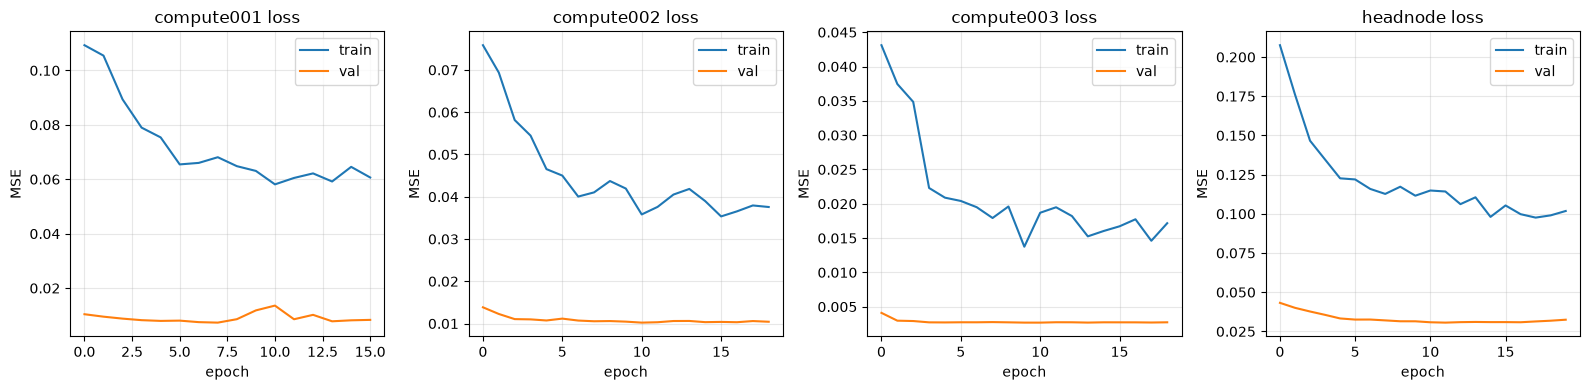

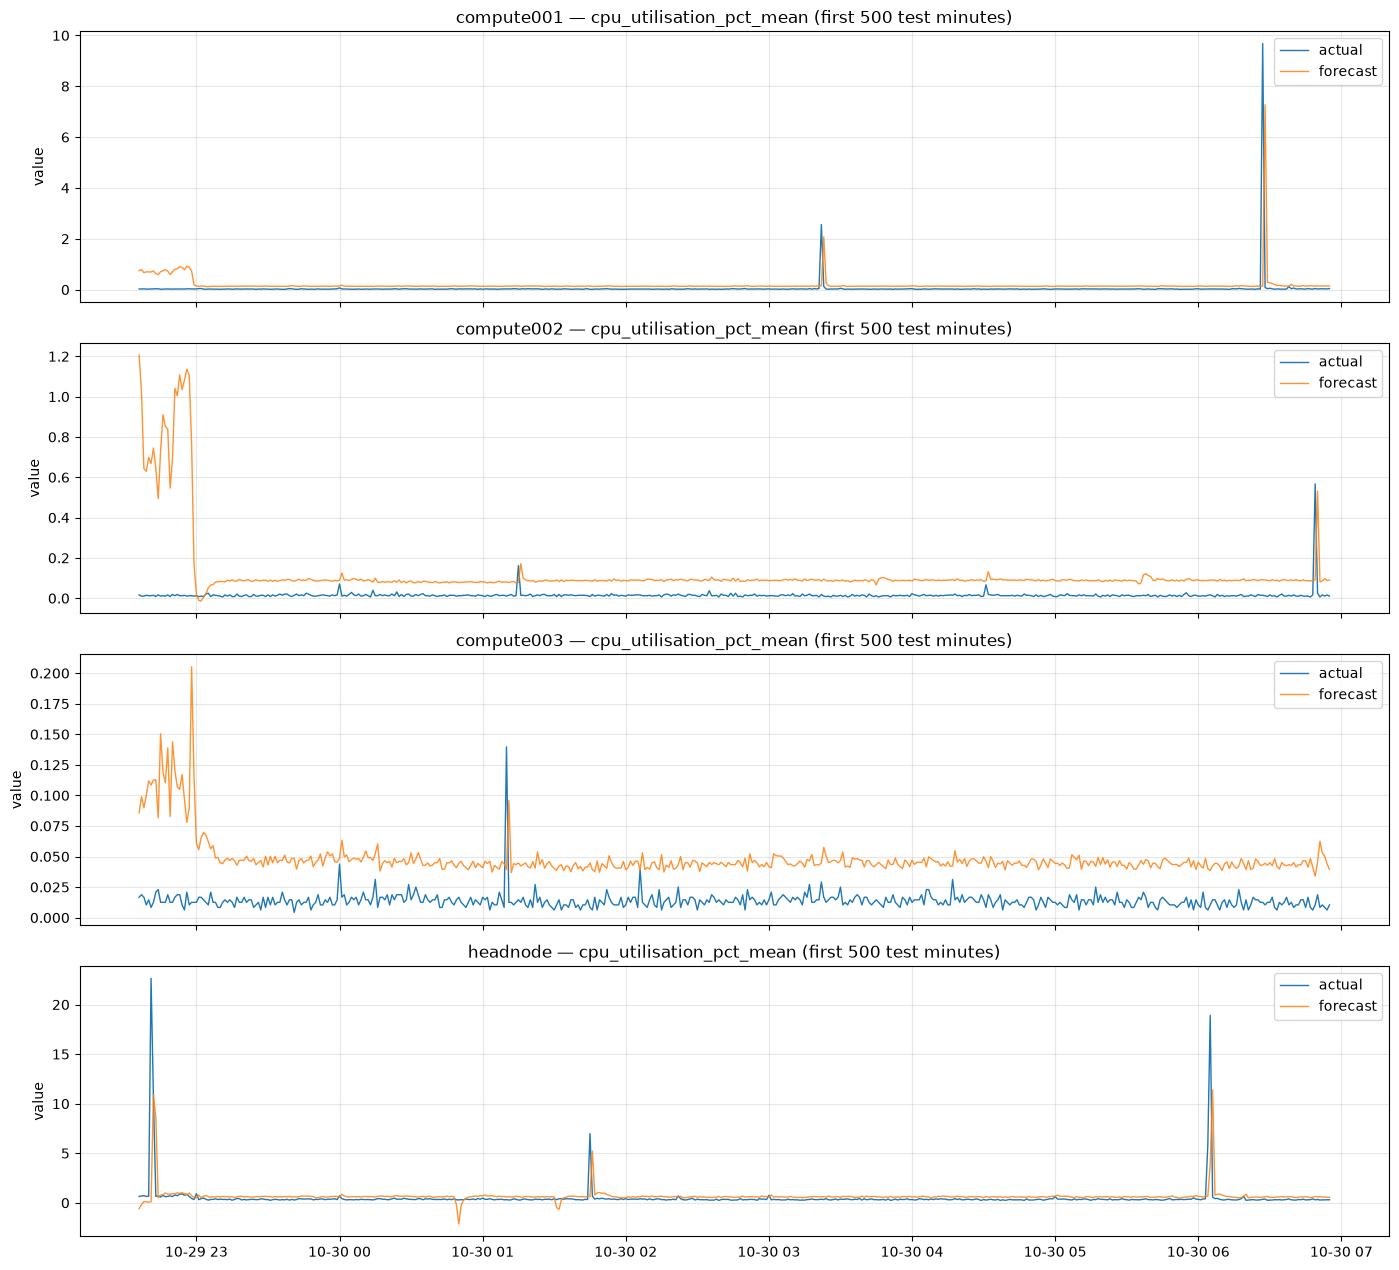

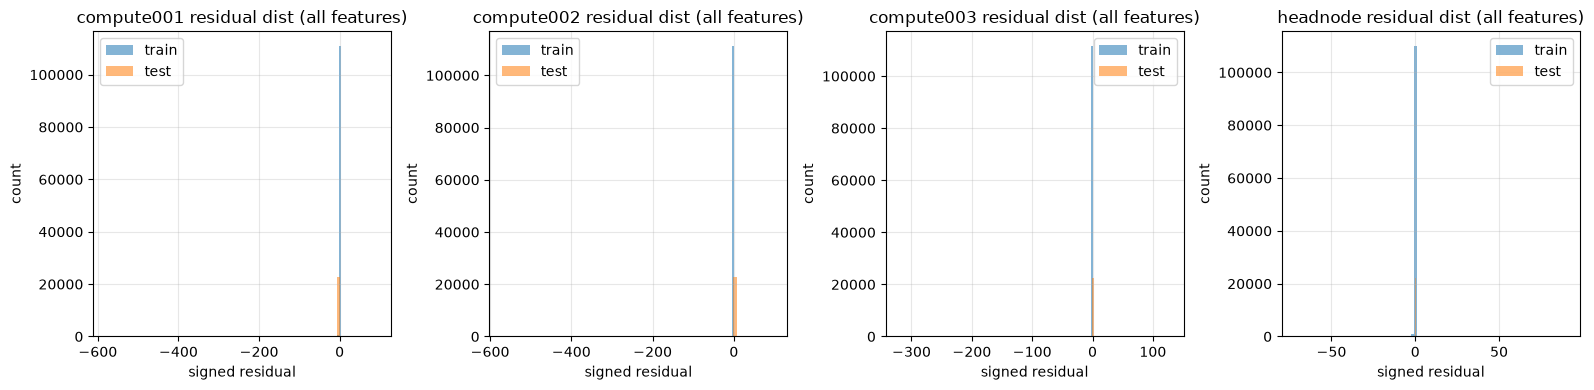

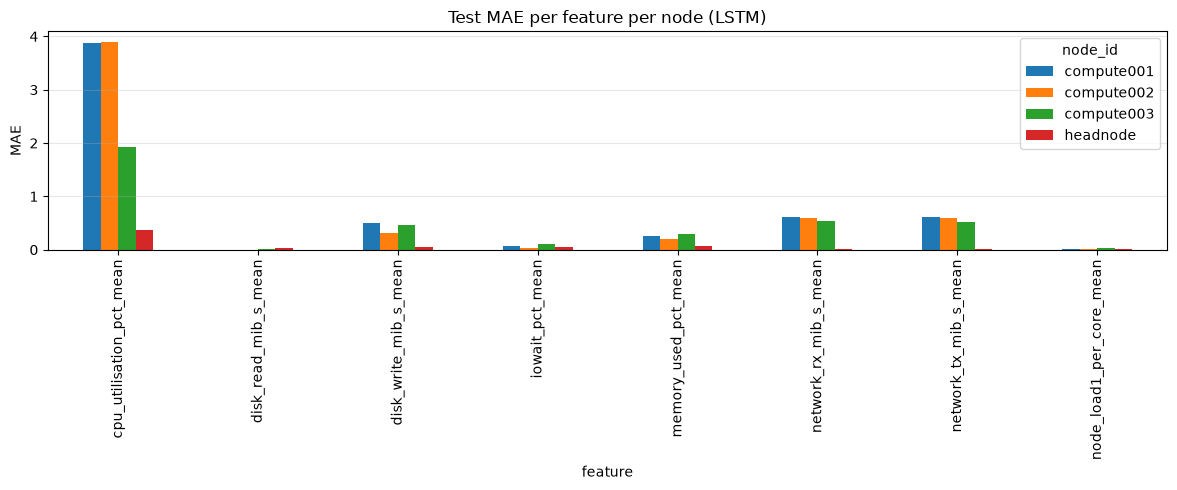

In [12]:
# --- 9.1 Loss curves --------------------------------------------------
fig, axes = plt.subplots(1, len(histories), figsize=(4 * len(histories), 4), squeeze=False)
for ax, (node, hist) in zip(axes[0], histories.items()):
    ax.plot(hist["train_loss"], label="train")
    ax.plot(hist["val_loss"],   label="val")
    ax.set_title(f"{node} loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "loss_curves.png", dpi=120)
plt.show()


# --- 9.2 Predicted vs actual -----------------------------------------
FEATURE_TO_PLOT = "cpu_utilisation_pct_mean"
f_idx = FEATURE_COLUMNS.index(FEATURE_TO_PLOT)
fig, axes = plt.subplots(len(trained), 1, figsize=(14, 3.2 * len(trained)), sharex=True)
if len(trained) == 1:
    axes = [axes]
for ax, node in zip(axes, trained.keys()):
    d = node_data[node]
    _, _, te_loader = make_loaders(node_data, node)
    pred, act = predict_split(trained[node], te_loader, DEVICE, d["scaler"])
    n_show = min(500, len(pred))
    t = d["times_test"][:n_show]
    ax.plot(t, act[:n_show, 0, f_idx],  label="actual",   linewidth=1.0)
    ax.plot(t, pred[:n_show, 0, f_idx], label="forecast", linewidth=1.0, alpha=0.85)
    ax.set_title(f"{node} — {FEATURE_TO_PLOT} (first {n_show} test minutes)")
    ax.set_ylabel("value"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(REPORT_DIR / "forecast_vs_actual.png", dpi=120)
plt.show()


# --- 9.3 Residual distributions --------------------------------------
fig, axes = plt.subplots(1, len(residual_details), figsize=(4 * len(residual_details), 4), squeeze=False)
for ax, (node, det) in zip(axes[0], residual_details.items()):
    ax.hist(det["tr_res"].ravel(), bins=80, alpha=0.55, label="train")
    ax.hist(det["te_res"].ravel(), bins=80, alpha=0.55, label="test")
    ax.set_title(f"{node} residual dist (all features)")
    ax.set_xlabel("signed residual"); ax.set_ylabel("count"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "residual_hist.png", dpi=120)
plt.show()


# --- 9.4 Per-node MAE bar chart ---------------------------------------
h1 = metrics_df[(metrics_df["split"] == "test") & (metrics_df["horizon_min"] == 1)]
pivot_mae = h1.pivot(index="feature", columns="node_id", values="MAE")
ax = pivot_mae.plot(kind="bar", figsize=(12, 5))
ax.set_title("Test MAE per feature per node (LSTM)")
ax.set_ylabel("MAE"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "mae_per_feature_node.png", dpi=120)
plt.show()

## 10. Save model bundle and inference smoke test

Each node's model + scaler is saved to `MODEL_DIR`. A config JSON captures the
architecture and feature list. The smoke test reloads the bundle and runs a
few forward passes to confirm the saved artifacts reproduce the same
predictions.

In [13]:
# Save each node's model
for node, model in trained.items():
    torch.save(model.state_dict(), MODEL_DIR / f"lstm_forecaster_v8_{node}.pt")
    joblib.dump(node_data[node]["scaler"], MODEL_DIR / f"lstm_scaler_v8_{node}.pkl")

# Save architecture + preprocessing config
config = {
    "features": FEATURE_COLUMNS,
    "lookback": LOOKBACK,
    "horizons": HORIZONS,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "train_end_time": str(TRAIN_END_TIME),
    "val_end_time": str(VAL_END_TIME),
    "residual_threshold_sigma": RESIDUAL_THRESHOLD_SIGMA,
    "nodes": list(trained.keys()),
}
with open(MODEL_DIR / "lstm_forecaster_v8_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved models, scalers, and config to:", MODEL_DIR)


# --- Smoke test -------------------------------------------------------
def reload_and_predict(node, n_samples=16):
    model = ResidualLSTMForecaster(
    n_features=len(FEATURE_COLUMNS),
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    n_horizons=len(HORIZONS),
    dropout=DROPOUT,
)
    model.load_state_dict(torch.load(MODEL_DIR / f"lstm_forecaster_v8_{node}.pt",
                                     map_location="cpu"))
    model.eval()
    X = torch.from_numpy(node_data[node]["X_test"][:n_samples]).float()
    with torch.no_grad():
        return model(X).cpu().numpy()


for node in trained.keys():
    pred = reload_and_predict(node)
    ref  = predict_split(trained[node],
                         DataLoader(WindowDataset(node_data[node]["X_test"][:16],
                                                  node_data[node]["y_test"][:16]),
                                    batch_size=16),
                         DEVICE, node_data[node]["scaler"])[0]
    # Compare in scaled space
    ref_scaled = (ref - node_data[node]["scaler"].mean_) / node_data[node]["scaler"].scale_
    ok = np.allclose(pred, ref_scaled, atol=1e-4)
    print(f"  [{node}] reload smoke test: {'PASS' if ok else 'FAIL'}")

Saved models, scalers, and config to: C:\Users\Admin\Documents\chpc\capstone project\models
  [compute001] reload smoke test: PASS
  [compute002] reload smoke test: PASS
  [compute003] reload smoke test: PASS
  [headnode] reload smoke test: PASS


## 11. Conclusion template — complete after running

Fill in from the printed tables:

- **Fit rows per node** (train / val / test window counts): ______
- **Best validation MSE per node**: ______
- **Test MAE (horizon=1) for `cpu_utilisation_pct_mean` per node**: ______
- **MAE improvement vs persistence baseline (%) per node**: ______
- **LSTM residual detector — AP for `is_any_anomaly` per node**: ______
- **LSTM residual detector — AP for `operational_event_window` per node**: ______
- **Precision / Recall / F1 at σ=3.0 per node**: ______
- **Alert burden** (flagged minutes / hour) per node: ______
- **Any node where the LSTM under-performs persistence**: ______

### Decision guidance

1. **Forecast accuracy**: If LSTM MAE is worse than persistence, the model is
   not capturing useful temporal structure. In that case reduce `LOOKBACK`,
   increase `EPOCHS`, or add more features.

2. **Residual anomaly detection**: If AP is low, the residual z-score is a
   weak detector. Consider:
   - Using a learned threshold (e.g., 99th percentile of training residual z)
   - Fusing with the Isolation Forest from V7 via OR-logic or a meta-classifier
   - Training the forecaster on longer windows (`LOOKBACK=120`)

3. **Comparison with V7 Isolation Forest**: The LSTM is not a replacement. It
   adds a *temporal* view. Report both on the same test split and quantify
   whether the union of alerts improves AP vs either detector alone.

4. **Before deploying**, re-train on a longer, untouched time period. The
   current test split was already inspected during V6/V7 development.

In [14]:
node = "headnode"
det = residual_details[node]
times = node_data[node]["times_test"]
mask = det["te_flags"] == 1

flagged_minutes = pd.DataFrame({
    "minute_utc": times[mask],
    "anomaly_score": det["te_score"][mask],
    "top_feature": [FEATURE_COLUMNS[i] for i in det["te_z"][mask].argmax(axis=1)],
    "max_z": det["te_z"][mask].max(axis=1),
}).sort_values("minute_utc")

flagged_minutes.to_csv(REPORT_DIR / "headnode_flagged_minutes.csv", index=False)
print(f"Flagged {len(flagged_minutes)} headnode minutes")
display(flagged_minutes.head(20))

Flagged 46 headnode minutes


,minute_utc,anomaly_score,top_feature,max_z
0,2026-10-29 22:36:00,7.545374,network_tx_mib_s_mean,7.545374
1,2026-10-29 22:38:00,3.896467,network_tx_mib_s_mean,3.896467
2,2026-10-29 22:41:00,52.967598,disk_read_mib_s_mean,52.967598
3,2026-10-29 22:42:00,20.621754,disk_read_mib_s_mean,20.621754
4,2026-10-29 22:43:00,4.313993,network_tx_mib_s_mean,4.313993
5,2026-10-29 22:44:00,9.423465,network_tx_mib_s_mean,9.423465
6,2026-10-29 22:45:00,3.353848,network_tx_mib_s_mean,3.353848
7,2026-10-29 22:46:00,10.008215,network_tx_mib_s_mean,10.008215
8,2026-10-29 22:47:00,11.671363,network_tx_mib_s_mean,11.671363
9,2026-10-29 22:49:00,11.930656,network_tx_mib_s_mean,11.930656
